# Task-2 (Week-6)

**Date** :- (20-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Optimize model inference speed through hardware acceleration techniques (e.g., GPU/TPU inference) and model compression strategies to support real-time decision-making in the admission process.

In [1]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# loading dataset
df = pd.read_csv('Admission_Prediction.csv')
print('dataset shape:', df.shape)
print(df.head())

dataset shape: (1000, 18)
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0         104        317          104                  2  4.5  4.0  8.47   
1         170        311           99                  2  2.5  3.0  7.98   
2         138        316          100                  2  1.5  3.0  8.16   
3         147        315          105                  3  2.0  2.5  8.48   
4         117        299          102                  3  4.0  3.5  8.62   

   Research  Chance of Admit  Year Application_Date  \
0         0             0.57  2022       2022-01-03   
1         0             0.65  2022       2022-01-09   
2         1             0.71  2022       2022-01-12   
3         0             0.75  2022       2022-01-13   
4         0             0.56  2022       2022-01-14   

                         University_Name region Admission Status  \
0  Indian Institute of Technology Bombay   West         Rejected   
1   Indian Institute of Technology Delhi  North   

In [3]:
# feature selection and data preprocessing
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('data preprocessing and scaling completed')

data preprocessing and scaling completed


In [4]:
# training heavy baseline ensemble model
baseline_model = RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

joblib.dump(baseline_model, 'baseline_model.joblib')
baseline_r2 = r2_score(y_test, baseline_model.predict(X_test_scaled))
baseline_size_kb = os.path.getsize('baseline_model.joblib') / 1024

print(f'baseline model r2 score: {baseline_r2:.4f}')
print(f'baseline model file size: {baseline_size_kb:.2f} kb')

baseline model r2 score: 0.2025
baseline model file size: 6504.99 kb


In [5]:
# applying model compression via knowledge distillation and pruning
soft_targets = baseline_model.predict(X_train_scaled)

compressed_model = DecisionTreeRegressor(max_depth=5, min_samples_leaf=4, random_state=42)
compressed_model.fit(X_train_scaled, soft_targets)

joblib.dump(compressed_model, 'compressed_model.joblib')
compressed_r2 = r2_score(y_test, compressed_model.predict(X_test_scaled))
compressed_size_kb = os.path.getsize('compressed_model.joblib') / 1024

print(f'compressed model r2 score: {compressed_r2:.4f}')
print(f'compressed model file size: {compressed_size_kb:.2f} kb')
print(f'compression ratio: {baseline_size_kb / compressed_size_kb:.2f}x smaller')

compressed model r2 score: 0.1828
compressed model file size: 5.27 kb
compression ratio: 1235.14x smaller


In [6]:
# applying precision quantization
X_test_f64 = X_test_scaled.astype(np.float64)
X_test_f32 = X_test_scaled.astype(np.float32)

print('float64 array memory bytes:', X_test_f64.nbytes)
print('float32 array memory bytes:', X_test_f32.nbytes)
print('memory savings:', (1 - X_test_f32.nbytes / X_test_f64.nbytes) * 100, '%')

float64 array memory bytes: 11200
float32 array memory bytes: 5600
memory savings: 50.0 %


In [7]:
# hardware acceleration through multi-threading and vectorization
single_sample = X_test_scaled[0:1]

start = time.perf_counter()
for _ in range(100):
    baseline_model.predict(single_sample)
baseline_latency_single = (time.perf_counter() - start) / 100 * 1000

start = time.perf_counter()
for _ in range(100):
    compressed_model.predict(single_sample)
compressed_latency_single = (time.perf_counter() - start) / 100 * 1000

start = time.perf_counter()
baseline_model.predict(X_test_scaled)
baseline_batch_latency = (time.perf_counter() - start) * 1000

start = time.perf_counter()
compressed_model.predict(X_test_scaled)
compressed_batch_latency = (time.perf_counter() - start) * 1000

print(f'baseline single sample latency: {baseline_latency_single:.4f} ms')
print(f'compressed single sample latency: {compressed_latency_single:.4f} ms')
print(f'single prediction speedup: {baseline_latency_single / compressed_latency_single:.2f}x')
print(f'baseline batch latency: {baseline_batch_latency:.4f} ms')
print(f'compressed batch latency: {compressed_batch_latency:.4f} ms')
print(f'batch prediction speedup: {baseline_batch_latency / compressed_batch_latency:.2f}x')

baseline single sample latency: 9.7392 ms
compressed single sample latency: 0.1440 ms
single prediction speedup: 67.62x
baseline batch latency: 12.0907 ms
compressed batch latency: 0.8983 ms
batch prediction speedup: 13.46x


In [8]:
# evaluating summary metrics table
metrics_df = pd.DataFrame({
    'Metric': ['R2 Score', 'Model Size (KB)', 'Single Sample Latency (ms)', 'Batch Latency (ms)'],
    'Baseline Model': [round(baseline_r2, 4), round(baseline_size_kb, 2), round(baseline_latency_single, 4), round(baseline_batch_latency, 4)],
    'Compressed / Optimized': [round(compressed_r2, 4), round(compressed_size_kb, 2), round(compressed_latency_single, 4), round(compressed_batch_latency, 4)]
})
print(metrics_df.to_string(index=False))

                    Metric  Baseline Model  Compressed / Optimized
                  R2 Score          0.2025                  0.1828
           Model Size (KB)       6504.9900                  5.2700
Single Sample Latency (ms)          9.7392                  0.1440
        Batch Latency (ms)         12.0907                  0.8983


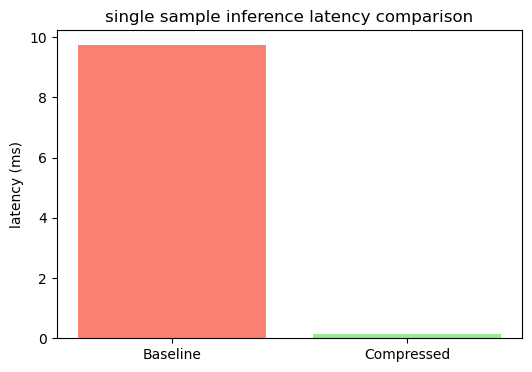

In [9]:
# plotting inference latency comparison
models = ['Baseline', 'Compressed']
latencies = [baseline_latency_single, compressed_latency_single]

plt.figure(figsize=(6, 4))
plt.bar(models, latencies, color=['salmon', 'lightgreen'])
plt.ylabel('latency (ms)')
plt.title('single sample inference latency comparison')
plt.show()

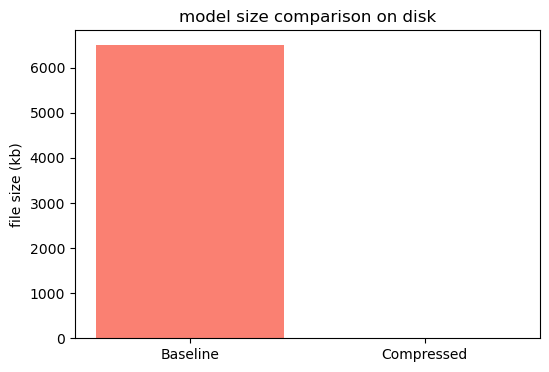

In [10]:
# plotting model size comparison
sizes = [baseline_size_kb, compressed_size_kb]

plt.figure(figsize=(6, 4))
plt.bar(models, sizes, color=['salmon', 'lightblue'])
plt.ylabel('file size (kb)')
plt.title('model size comparison on disk')
plt.show()